# Code 3: Optimising a rotation gate

This notebook goes with the section *Optimising a rotation gate* in [Lecture 3](../content/lectures/lecture3.md). It is our first **variational** algorithm: a circuit with adjustable angles, a loss function we estimate by measuring, and a classical optimiser that updates the angles. VQE and quantum machine learning (Lectures 4 to 6) use exactly the same loop, just with bigger circuits.

The steps are:
1. prepare a fixed initial state $|\psi_\text{initial}\rangle = R_Z(\theta_1)R_Y(\theta_2)|0\rangle$,
2. apply a general rotation $U(\vec\phi) = R_Z(\phi_1)R_Y(\phi_2)R_Z(\phi_3)$,
3. measure the Bloch vector $\vec r(\vec\phi)$ (tomography),
4. compute the loss $L(\vec\phi) = |\vec r(\vec\phi) - \vec r_\text{target}|$,
5. update $\vec\phi$ by gradient descent, with the gradient from finite differences.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from qiskit import QuantumCircuit
from qiskit.circuit import ParameterVector
from qiskit.quantum_info import SparsePauliOp
from qiskit.primitives import StatevectorEstimator

rng = np.random.default_rng(4041)       # seeded random numbers: reproducible results

In [2]:
def plot_bloch_sphere(ax=None):
    """Draw an empty Bloch sphere with labelled x, y, z axes. Returns the 3D axes."""
    if ax is None:
        fig = plt.figure(figsize=(5, 5))
        ax = fig.add_subplot(projection="3d")
    u, v = np.mgrid[0:np.pi:31j, 0:2 * np.pi:30j]
    ax.plot_wireframe(np.sin(u) * np.cos(v), np.sin(u) * np.sin(v), np.cos(u), color="k", alpha=0.08)
    t = np.linspace(0, 2 * np.pi, 100)
    ax.plot(np.cos(t), np.sin(t), 0, color="k", alpha=0.2)            # equator
    for vec, lab in zip(np.eye(3), ["x", "y", "z"]):
        ax.quiver(0, 0, 0, *(1.3 * vec), color="k", arrow_length_ratio=0.08)
        ax.text(*(1.45 * vec), lab, fontsize=13)
    ax.set_box_aspect([1, 1, 1])
    ax.set_axis_off()
    return ax

## The parametrised circuit

We use a `ParameterVector` for the three angles. The circuit is built **once**; the Estimator then runs it for whatever angles we pass in. Note the order: $U = R_Z(\phi_1)R_Y(\phi_2)R_Z(\phi_3)$ means $R_Z(\phi_3)$ acts **first**, so it comes first in the circuit.

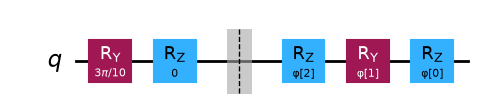

In [3]:
theta_initial = (0.0, 0.3 * np.pi)          # (theta_1, theta_2) for the initial state
phi = ParameterVector("φ", 3)

qc = QuantumCircuit(1)
qc.ry(theta_initial[1], 0)                  # initial state
qc.rz(theta_initial[0], 0)
qc.barrier()
qc.rz(phi[2], 0)                            # U(phi) = RZ(phi_1) RY(phi_2) RZ(phi_3)
qc.ry(phi[1], 0)
qc.rz(phi[0], 0)
qc.draw("mpl")

## Measuring the Bloch vector

The Estimator returns $\langle X\rangle, \langle Y\rangle, \langle Z\rangle$. Its `precision` option mimics a finite number of shots: `precision` $= 1/\sqrt{\text{shots}}$ adds the matching amount of random statistical noise. `precision=0` gives exact expectation values.

In [4]:
observables = [[SparsePauliOp(p)] for p in "XYZ"]     # shape (3, 1) so it broadcasts against many angle sets

def bloch_vectors(angle_sets, shots=None):
    # Bloch vectors for an array of angle sets with shape (N, 3). Returns shape (N, 3).
    estimator = StatevectorEstimator(seed=rng.integers(1e9))
    precision = 0.0 if shots is None else 1 / np.sqrt(shots)
    evs = estimator.run([(qc, observables, np.atleast_2d(angle_sets))], precision=precision).result()[0].data.evs
    return evs.T

def loss(r, r_target):
    return np.linalg.norm(r - r_target, axis=-1)

# a random target on the Bloch sphere
r_target = rng.normal(size=3)
r_target /= np.linalg.norm(r_target)

r0 = bloch_vectors([0, 0, 0])[0]
print("initial Bloch vector:", r0.round(3))
print("target Bloch vector :", r_target.round(3))
print("initial loss        :", loss(r0, r_target).round(3))

initial Bloch vector: [0.809 0.    0.588]
target Bloch vector : [0.346 0.63  0.695]
initial loss        : 0.789


## Gradient descent with finite differences

For each angle $\phi_i$ we use the central finite difference

$$
\frac{\partial L}{\partial\phi_i} \approx \frac{L(\vec\phi + c\,\vec e_i) - L(\vec\phi - c\,\vec e_i)}{2c},
$$

then step downhill: $\vec\phi \leftarrow \vec\phi - \eta\,\nabla L$. Each iteration needs $2\times 3 = 6$ tomography runs for the gradient, plus one to record where we are. We send all 7 angle sets to the Estimator in a **single** call.

In [5]:
def optimise(n_iterations=60, c=0.1, eta=0.1, shots=None, phi0=(0.0, 0.0, 0.0)):
    phis = np.array(phi0, dtype=float)
    shifts = np.vstack([np.zeros(3), c * np.eye(3), -c * np.eye(3)])     # (7, 3)
    history = {"phi": [], "r": [], "loss": []}
    for _ in range(n_iterations):
        r = bloch_vectors(phis + shifts, shots)        # 7 Bloch vectors in one call
        L = loss(r, r_target)
        grad = (L[1:4] - L[4:7]) / (2 * c)
        history["phi"].append(phis.copy())
        history["r"].append(r[0])
        history["loss"].append(L[0])
        phis = phis - eta * grad
    return phis, {k: np.array(v) for k, v in history.items()}

phi_exact, hist_exact = optimise()
phi_shots, hist_shots = optimise(shots=1000)
print("optimised angles (exact):", phi_exact.round(3))

optimised angles (exact): [ 0.468 -0.165  0.526]


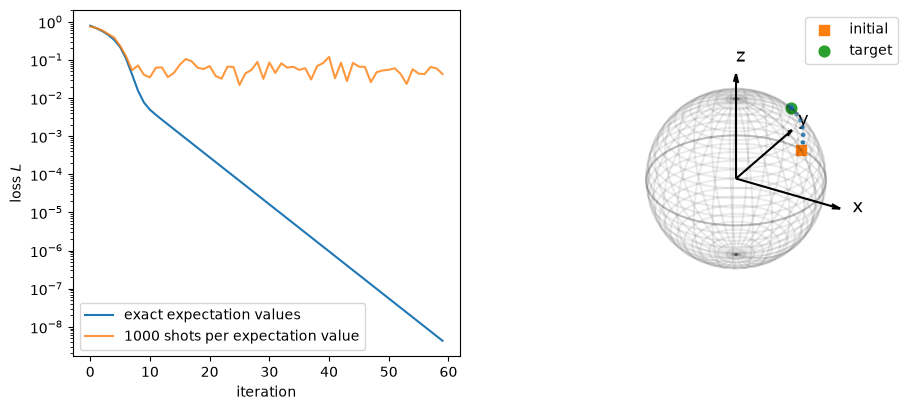

In [6]:
fig = plt.figure(figsize=(11, 4.5))
ax1 = fig.add_subplot(1, 2, 1)
ax1.plot(hist_exact["loss"], label="exact expectation values")
ax1.plot(hist_shots["loss"], label="1000 shots per expectation value", alpha=0.8)
ax1.set_yscale("log")
ax1.set_xlabel("iteration")
ax1.set_ylabel("loss $L$")
ax1.legend()

ax2 = plot_bloch_sphere(fig.add_subplot(1, 2, 2, projection="3d"))
ax2.scatter(*hist_exact["r"].T, marker=".", c="C0")
ax2.scatter(*hist_exact["r"][0], marker="s", s=60, c="C1", label="initial")
ax2.scatter(*r_target, s=60, c="C2", label="target")
ax2.legend()
plt.show()

With exact expectation values the loss falls to (numerically) zero. With 1000 shots it stalls at a **noise floor** of a few times $1/\sqrt{1000}\approx 0.03$. Once the true loss is smaller than the statistical error on each expectation value, the finite-difference gradient is mostly noise. This is a central practical issue for every variational algorithm on real hardware, and it is the starting point for Lecture 5.

````{admonition} Try this
:class: tip
1. (Exercise 3.3.1) Make the initial state random.
2. (Exercise 3.3.2) Optimise $U = R_X(\phi_1)R_Y(\phi_2)R_X(\phi_3)$ instead. Does it still work?
3. (Exercise 3.3.3) Remove the square root from the loss. What changes near the target, and why? *Hint:* think about the gradient of $|x|$ versus $x^2$ near $x=0$.
4. Re-run with learning rate `eta=0.2`. The exact loss now gets stuck bouncing around $L\approx 0.1$. Why? *Hint:* what is the magnitude of the gradient of a distance $|\vec r - \vec r_\text{target}|$, even very close to the target?
5. How does the finite-difference step $c$ affect convergence? What goes wrong if $c$ is very small **with shot noise**?
````